In [3]:
"""
加利福尼亚房价预测 
"""
# ================= ① 加载数据,分好三个集合 =================
from sklearn.model_selection import train_test_split
import csv
import numpy as np

with open("C:\\Users\\hufengji\\Desktop\\11\\california_housing.csv", encoding="utf-8") as f:
    rows = list(csv.reader(f))[1:]          
X = np.array([[float(v) for v in r[:8]] for r in rows])
y = np.array([float(r[8]) for r in rows])

# 8 个数值特征:收入、房龄、平均房间数、平均卧室数、人口、平均居住人数、纬度、经度
# 目标 y:房价中位数(单位 10 万美元)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)   # (12384, 8) (4128, 8) (4128, 8)

(12384, 8) (4128, 8) (4128, 8)


In [5]:
# ================= ② 构建 Pipeline 并训练 =================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

model = Pipeline([
    ("scaler", StandardScaler()),   # 摆正数据:均值 0、方差 1
    ("ridge", Ridge(alpha=1.0)),    # 岭回归:带正则化的线性回归
])
model.fit(X_train, y_train)

# ================= ③ 在验证集上看指标 =================
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_val)
rmse = mean_squared_error(y_val, y_pred) ** 0.5

print(f"RMSE = {rmse:.3f}   R² = {r2_score(y_val, y_pred):.3f}")   # 约 RMSE = 0.730   R² = 0.592

RMSE = 0.730   R² = 0.592


In [6]:
# ================= ④ 用 GridSearchCV 调参 =================
from sklearn.model_selection import GridSearchCV

param_grid = {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(model, param_grid, cv=5)
grid.fit(X_train, y_train)

print(grid.best_params_, round(grid.best_score_, 3))               # 约 {'ridge__alpha': 0.01} 0.61
print(round(r2_score(y_val, grid.predict(X_val)), 3))              # 约 0.592

{'ridge__alpha': 0.01} 0.61
0.592


样本量: [ 990 2972 4953 6934 9907]
训练 R²: [0.679 0.637 0.619 0.617 0.612]
验证 R²: [-13.385  -0.608   0.611   0.61    0.61 ]


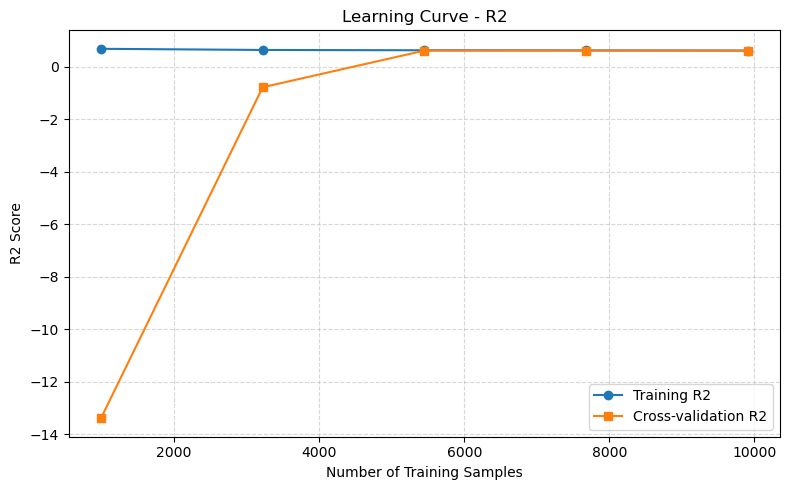

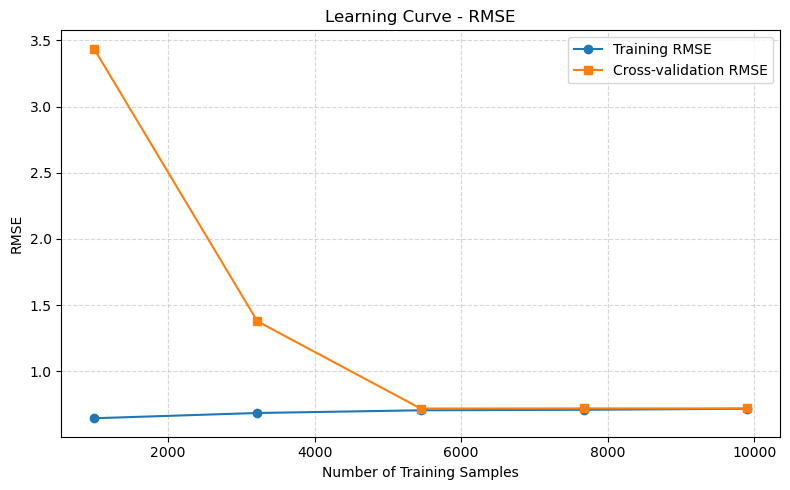

In [6]:
# ================= ⑤ 学习曲线:指标还能往哪儿提 =================
from sklearn.model_selection import learning_curve

sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train, cv=5, scoring="r2",
    train_sizes=[0.1, 0.3, 0.5, 0.7, 1.0])

print("样本量:", sizes)
print("训练 R²:", np.mean(train_scores, axis=1).round(3))
print("验证 R²:", np.mean(val_scores, axis=1).round(3))
# 读法:两条线都低且贴近 -> 欠拟合;训练高验证低、缺口不收窄 -> 过拟合;
#      两条线收敛到接近的高分 -> 瓶颈在数据,提指标靠特征工程。



# ================= ⑤ 学习曲线：R² 和 RMSE =================
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# 为了便于观察，统一设置训练样本量比例
train_sizes_ratio = np.linspace(0.1, 1.0, 5)

# ---------- 图一：R² 学习曲线 ----------
sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    train_sizes=train_sizes_ratio,
    n_jobs=-1
)

# 对 5 折交叉验证的结果求均值和标准差
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)

val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, "o-", label="Training R2")
plt.plot(sizes, val_mean, "s-", label="Cross-validation R2")

# # 阴影表示不同折之间的波动范围
# plt.fill_between(
#     sizes, train_mean - train_std, train_mean + train_std,
#     alpha=0.15
# )
# plt.fill_between(
#     sizes, val_mean - val_std, val_mean + val_std,
#     alpha=0.15
# )

plt.xlabel("Number of Training Samples")
plt.ylabel("R2 Score")
plt.title("Learning Curve - R2")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("learning_curve_r2.png", dpi=300)
plt.show()


# ---------- 图二：RMSE 学习曲线 ----------
# 注意：learning_curve 的 scoring 支持负 RMSE，
# 因为 sklearn 统一规定分数越高越好。
sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    train_sizes=train_sizes_ratio,
    n_jobs=-1
)

# 负 RMSE 转换为正 RMSE，方便理解
train_rmse = -train_scores
val_rmse = -val_scores

train_mean = np.mean(train_rmse, axis=1)
train_std = np.std(train_rmse, axis=1)

val_mean = np.mean(val_rmse, axis=1)
val_std = np.std(val_rmse, axis=1)

plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, "o-", label="Training RMSE")
plt.plot(sizes, val_mean, "s-", label="Cross-validation RMSE")

# plt.fill_between(
#     sizes, train_mean - train_std, train_mean + train_std,
#     alpha=0.15
# )
# plt.fill_between(
#     sizes, val_mean - val_std, val_mean + val_std,
#     alpha=0.15
# )

plt.xlabel("Number of Training Samples")
plt.ylabel("RMSE")
plt.title("Learning Curve - RMSE")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("learning_curve_rmse.png", dpi=300)
plt.show()